# Análise de vendas e desempenho gerencial

Este projeto analisa as vendas de produtos tecnológicos por loja e região e compara o faturamento mensal das lojas com as metas dos respectivos gerentes. A análise combina os registros de vendas (`vendas_tech.csv`) com o cadastro de gerentes e suas metas (`gerentes_lojas.xlsx`).

Para responder às perguntas de negócio, será calculado o faturamento de cada venda (`Preco_Unitario * Qtd`), a região será identificada a partir da loja e os resultados serão agregados conforme cada objetivo. Como as metas são mensais, a comparação com as vendas também deverá ser feita mês a mês.

## Objetivos da análise

1. Identificar a região com maior faturamento.
2. Verificar se todos os gerentes atingiram as metas mensais das lojas sob sua responsabilidade.
3. Identificar o produto mais vendido em cada região, considerando a quantidade de unidades (`Qtd`).

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # For reproducibility


df_vendas = pd.read_csv('../data/vendas_tech.csv', low_memory=False)
df_gerentes = pd.read_excel('../data/gerentes_lojas.xlsx')

df_objetivos = pd.DataFrame([
    {
        'Objetivo': 'Encontrar a região com maior faturamento',
        'Colunas de origem': 'Loja (vendas)',
        'Colunas derivadas/apoio': 'Regiao (mapeada a partir de Loja); Faturamento = Preco_Unitario * Qtd',
        'Análise prevista': 'Somar Faturamento por Regiao e ordenar do maior para o menor.'
    },
    {
        'Objetivo': 'Verificar se cada gerente atingiu a meta mensal',
        'Colunas de origem': 'Loja, Data, Preco_Unitario, Qtd (vendas); Loja, Gerente, Meta_Mensal (gerentes)',
        'Colunas derivadas/apoio': 'Mes (derivado de Data); Faturamento = Preco_Unitario * Qtd; Meta_Atingida (resultado da comparação)',
        'Análise prevista': 'Associar as tabelas por Loja, somar Faturamento por Loja, Gerente e Mes e comparar com Meta_Mensal.'
    },
    {
        'Objetivo': 'Encontrar o produto mais vendido em cada região',
        'Colunas de origem': 'Loja, Produto, Qtd (vendas)',
        'Colunas derivadas/apoio': 'Regiao (mapeada a partir de Loja); unidades vendidas (soma de Qtd)',
        'Análise prevista': 'Somar Qtd por Regiao e Produto e selecionar o produto com maior quantidade em cada região.'
    }
])

display(df_objetivos)



,Objetivo,Colunas de origem,Colunas derivadas/apoio,Análise prevista
0,Encontrar a região com maior faturamento,Loja (vendas),Regiao (mapeada a partir de Loja); Faturamento...,Somar Faturamento por Regiao e ordenar do maio...
1,Verificar se cada gerente atingiu a meta mensal,"Loja, Data, Preco_Unitario, Qtd (vendas); Loja...",Mes (derivado de Data); Faturamento = Preco_Un...,"Associar as tabelas por Loja, somar Faturament..."
2,Encontrar o produto mais vendido em cada região,"Loja, Produto, Qtd (vendas)",Regiao (mapeada a partir de Loja); unidades ve...,Somar Qtd por Regiao e Produto e selecionar o ...


# Etapa inicial: análise dos dois DataFrames

In [33]:
#Analise do dataframe de vendas e gerentes.
display(df_vendas.head())
display(df_gerentes.head())

df_vendas.info()
df_gerentes.info()

#Como df_gerentes estão com os dados certos e nenhum tratamento será necessário, o fovo inicial vai ser o df_vendas

,ID_Pedido,Data,Loja,Produto,Preco_Unitario,Qtd,Cliente,Data_Base
0,1,2023-06-08,São Paulo,Mouse Gamer,120.0,1,Cliente_4095,2025-01-01
1,2,2023-03-01,Belo Horizonte,iPhone 14,5500.0,1,Cliente_8750,NaN
2,3,2023-02-25,NaN,"Monitor 27""",1200.0,1,Cliente_14859,NaN
3,4,2024-11-19,RIO DE JANEIRO,Mouse Gamer,120.0,2,Cliente_17343,NaN
4,5,2024-01-27,Rio de Janeiro,Smartphone Samsung,2200.0,1,Cliente_23377,NaN


,Loja,Gerente,Meta_Mensal
0,São Paulo,Carlos,50000
1,Rio de Janeiro,Fernanda,60000
2,Curitiba,Roberto,45000
3,Belo Horizonte,Juliana,55000
4,Recife,Marcos,48000


<class 'pandas.DataFrame'>
RangeIndex: 100100 entries, 0 to 100099
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   ID_Pedido       100100 non-null  int64  
 1   Data            100100 non-null  str    
 2   Loja            98099 non-null   str    
 3   Produto         100100 non-null  str    
 4   Preco_Unitario  100100 non-null  float64
 5   Qtd             100100 non-null  int64  
 6   Cliente         100100 non-null  str    
 7   Data_Base       1 non-null       str    
dtypes: float64(1), int64(2), str(5)
memory usage: 6.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Loja         7 non-null      str  
 1   Gerente      7 non-null      str  
 2   Meta_Mensal  7 non-null      int64
dtypes: int64(1), str(2)
memory usage: 300.0 bytes


# 1 - Tratamento de dados: padronização

A análise de `df_vendas.info()` mostra que a coluna `Data` está armazenada como texto. Além disso, a coluna `Loja` apresenta diferentes grafias e espaços em branco. Também foi informado pela equipe que os valores nulos em `Loja` representam vendas realizadas online.

## Tarefas

1. Converter a coluna `Data` para o tipo `datetime`.
2. Substituir os valores nulos da coluna `Loja` por `Online`.
3. Padronizar os nomes da coluna `Loja`.

In [34]:
#Transformação da coluna Data para o tipo datetime

df_vendas["Data"] = pd.to_datetime(df_vendas["Data"], format="%Y-%m-%d")
df_vendas.info()

#Transformando Nan em Online na coluna Loja, pois as vendas online não possuem loja física.
df_vendas["Loja"] = df_vendas["Loja"].fillna("Online")

#Padronizando a coluna Loja
df_vendas["Loja"] = df_vendas["Loja"].str.strip().str.title()


display(df_vendas.sample(12), SEED=42)



<class 'pandas.DataFrame'>
RangeIndex: 100100 entries, 0 to 100099
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   ID_Pedido       100100 non-null  int64         
 1   Data            100100 non-null  datetime64[us]
 2   Loja            98099 non-null   str           
 3   Produto         100100 non-null  str           
 4   Preco_Unitario  100100 non-null  float64       
 5   Qtd             100100 non-null  int64         
 6   Cliente         100100 non-null  str           
 7   Data_Base       1 non-null       str           
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 6.1 MB


,ID_Pedido,Data,Loja,Produto,Preco_Unitario,Qtd,Cliente,Data_Base
39897,39898,2023-07-27,Belo Horizonte,"Monitor 27""",1200.0,1,Cliente_26586,NaN
32984,32985,2023-12-10,Recife,Notebook Dell,3500.0,1,Cliente_3070,NaN
33816,33817,2024-07-24,Salvador,"Monitor 27""",1200.0,1,Cliente_280,NaN
21129,21130,2024-10-23,Belo Horizonte,Notebook Dell,3500.0,1,Cliente_5458,NaN
89669,89670,2023-08-03,Rio De Janeiro,Smartphone Samsung,2200.0,1,Cliente_17285,NaN
578,579,2023-06-10,Porto Alegre,Notebook HP,3200.0,2,Cliente_17833,NaN
53361,53362,2023-06-05,São Paulo,Mouse Gamer,120.0,1,Cliente_2382,NaN
69232,69233,2024-08-19,Salvador,"Monitor 27""",1200.0,1,Cliente_5990,NaN
39219,39220,2023-05-04,Curitiba,Smartphone Samsung,2200.0,1,Cliente_27719,NaN
980,981,2024-08-20,Curitiba,iPhone 14,5500.0,1,Cliente_28793,NaN


# 2 - Tratamento de dados: valores nulos e duplicatas

## Tratamento da coluna `Data_Base`

1. Verificar a quantidade e o percentual de valores nulos antes de decidir o tratamento.
2. Avaliar se a coluna é necessária para os objetivos e se existe uma regra confiável para preencher os valores ausentes.
3. Neste conjunto, `Data_Base` possui 100.099 valores nulos em 100.100 registros, aproximadamente 99,999% da coluna, além de apenas um valor preenchido. Como ela não é necessária para as análises propostas e não há uma base suficiente para imputar os demais registros, remover a coluna é mais adequado do que preencher quase todos os valores por suposição.

## Tratamento das duplicatas

1. Considerar como duplicata o registro que repete a combinação de `ID_Pedido` e `Cliente`.
2. Manter a primeira ocorrência e remover as demais. A verificação encontrou 100 repetições dessa chave, todas também consideradas duplicatas completas.
3. Conferir a quantidade removida e garantir que não restem repetições da combinação entre `ID_Pedido` e `Cliente`.

In [35]:
# Avaliação dos valores ausentes em Data_Base
total_registros = len(df_vendas)
nulos_data_base = int(df_vendas['Data_Base'].isna().sum())
percentual_nulos_data_base = nulos_data_base / total_registros * 100

print(f'Valores nulos em Data_Base: {nulos_data_base} de {total_registros} ({percentual_nulos_data_base:.3f}%).')

# Identificação de duplicatas pela combinação solicitada
chaves_duplicidade = ['ID_Pedido', 'Cliente']
duplicatas_por_chave = int(df_vendas.duplicated(subset=chaves_duplicidade).sum())
duplicatas_completas = int(df_vendas.duplicated().sum())
print(f'Repetições de ID_Pedido + Cliente: {duplicatas_por_chave}.')
print(f'Duplicatas completas encontradas: {duplicatas_completas}.')

# Remoção da coluna sem dados suficientes e das repetições da chave
df_vendas = df_vendas.drop(columns=['Data_Base'])
df_vendas = df_vendas.drop_duplicates(subset=chaves_duplicidade, keep='first').copy()

print(f'Registros restantes: {len(df_vendas)}.')
print(f'Repetições restantes de ID_Pedido + Cliente: {df_vendas.duplicated(subset=chaves_duplicidade).sum()}.')
display(df_vendas.sample(12), SEED=42)

Valores nulos em Data_Base: 100099 de 100100 (99.999%).
Repetições de ID_Pedido + Cliente: 100.
Duplicatas completas encontradas: 100.
Registros restantes: 100000.
Repetições restantes de ID_Pedido + Cliente: 0.


,ID_Pedido,Data,Loja,Produto,Preco_Unitario,Qtd,Cliente
18886,18887,2023-02-23,São Paulo,Mouse Gamer,120.0,1,Cliente_14658
52475,52476,2023-01-02,Recife,Teclado Mecânico,250.0,1,Cliente_15762
42455,42456,2023-05-27,Curitiba,Teclado Mecânico,250.0,1,Cliente_27965
39935,39936,2024-03-26,Belo Horizonte,Cabo HDMI,40.0,1,Cliente_11036
69215,69216,2024-01-09,São Paulo,Teclado Mecânico,250.0,1,Cliente_17045
43842,43843,2023-03-24,Porto Alegre,"Monitor 27""",1200.0,1,Cliente_3932
50625,50626,2024-01-08,Belo Horizonte,Smartphone Samsung,2200.0,2,Cliente_24484
12971,12972,2023-12-05,Porto Alegre,Cabo HDMI,40.0,1,Cliente_23207
85305,85306,2024-01-02,Porto Alegre,Cabo HDMI,40.0,1,Cliente_1666
79360,79361,2023-01-07,Recife,Teclado Mecânico,250.0,1,Cliente_6805


## Preparação concluída: base pronta para análise

Com o tratamento dos valores ausentes e das duplicatas, encerramos a etapa de limpeza. A tabela também recebeu colunas derivadas que organizam as informações e serão úteis nas próximas análises:

- **`Faturamento`**: calculado por `Preco_Unitario * Qtd`; será usado para comparar o resultado das regiões.
- **`Regiao`**: identificada a partir da `Loja`; permitirá agrupar as vendas por região.
- **`Forma_de_venda`**: diferencia vendas `Online` e `Presencial`.

Essas variáveis apoiam a análise do faturamento regional e dos produtos mais vendidos. Para avaliar as metas dos gerentes, a próxima etapa também deverá considerar o mês da venda e relacionar as vendas ao cadastro de gerentes e metas.

In [36]:
df_vendas["Faturamento"] = df_vendas["Preco_Unitario"] * df_vendas["Qtd"]
df_vendas["Loja"].unique()

r = {
"São Paulo": "Sudeste",
"Rio De Janeiro": "Sudeste",
"Minas Gerais": "Sudeste",
"Recife": "Nordeste",
"Salvador": "Nordeste",
"Porto Alegre": "Sul",
"Belo Horizonte": "Sudeste",
"Curitiba": "Sul",
"Online": "Online"
}

df_vendas["Regiao"] = df_vendas["Loja"].map(r)
df_vendas["Forma_de_venda"] = np.where(df_vendas["Loja"] =="Online", "Online", "Presencial")

df_vendas

,ID_Pedido,Data,Loja,Produto,Preco_Unitario,Qtd,Cliente,Faturamento,Regiao,Forma_de_venda
0,1,2023-06-08,São Paulo,Mouse Gamer,120.0,1,Cliente_4095,120.0,Sudeste,Presencial
1,2,2023-03-01,Belo Horizonte,iPhone 14,5500.0,1,Cliente_8750,5500.0,Sudeste,Presencial
2,3,2023-02-25,Online,"Monitor 27""",1200.0,1,Cliente_14859,1200.0,Online,Online
3,4,2024-11-19,Rio De Janeiro,Mouse Gamer,120.0,2,Cliente_17343,240.0,Sudeste,Presencial
4,5,2024-01-27,Rio De Janeiro,Smartphone Samsung,2200.0,1,Cliente_23377,2200.0,Sudeste,Presencial
...,...,...,...,...,...,...,...,...,...,...
99995,99996,2023-01-24,São Paulo,Mouse Gamer,120.0,2,Cliente_13732,240.0,Sudeste,Presencial
99996,99997,2024-08-28,Rio De Janeiro,Cabo HDMI,40.0,1,Cliente_25058,40.0,Sudeste,Presencial
99997,99998,2024-03-18,Curitiba,Smartphone Samsung,2200.0,2,Cliente_28864,4400.0,Sul,Presencial
99998,99999,2023-11-04,Porto Alegre,iPhone 14,5500.0,1,Cliente_4205,5500.0,Sul,Presencial


## Faturamento total por região

Para descobrir qual região teve o maior faturamento, somamos a coluna `Faturamento` para cada região e ordenamos os totais do maior para o menor. A primeira linha do resultado identifica a região líder.

As vendas `Online` não são incluídas nessa comparação, pois não representam uma região geográfica. Os valores são apresentados em reais (R$), mantendo a coluna numérica original disponível para outros cálculos.

In [37]:
# Soma o faturamento das regiões geográficas e ordena do maior para o menor.
df_faturamento_por_regiao = (
    df_vendas.loc[df_vendas["Regiao"] != "Online"]
    .groupby("Regiao", as_index=False)["Faturamento"]
    .sum()
    .sort_values("Faturamento", ascending=False)
    .reset_index(drop=True)
)

# Formata uma cópia para exibição, preservando os valores numéricos originais.
df_faturamento_formatado = df_faturamento_por_regiao.rename(
    columns={"Regiao": "Região", "Faturamento": "Faturamento total"}
).copy()
df_faturamento_formatado.to_csv("../resultados/faturamento_por_regiao.csv", index=False)
df_faturamento_formatado["Faturamento total"] = df_faturamento_formatado["Faturamento total"].map(
    lambda valor: f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)



display(df_faturamento_formatado)

,Região,Faturamento total
0,Sudeste,"R$ 126.100.300,00"
1,Nordeste,"R$ 84.491.000,00"
2,Sul,"R$ 82.800.180,00"


In [38]:
# Objetivo 2: comparar o faturamento mensal de cada loja com a meta do gerente.
df_gerentes_meta = df_gerentes[["Loja", "Gerente", "Meta_Mensal"]].copy()
df_gerentes_meta["Loja"] = df_gerentes_meta["Loja"].str.strip().str.title()

df_vendas_meta = df_vendas[["Loja", "Data", "Faturamento"]].copy()
df_vendas_meta["Loja"] = df_vendas_meta["Loja"].str.strip().str.title()
df_vendas_meta["Mes"] = df_vendas_meta["Data"].dt.to_period("M").astype(str)

# Cria uma linha para cada loja e mês, inclusive quando não houve vendas.
meses = pd.period_range(
    start=df_vendas_meta["Data"].min().to_period("M"),
    end=df_vendas_meta["Data"].max().to_period("M"),
    freq="M"
).astype(str)
calendario_mensal = pd.MultiIndex.from_product(
    [df_gerentes_meta["Loja"], meses],
    names=["Loja", "Mes"]
).to_frame(index=False)

faturamento_mensal = (
    df_vendas_meta.groupby(["Loja", "Mes"], as_index=False)
    .agg(Faturamento_Mensal=("Faturamento", "sum"))
)
df_metas_mensais = (
    calendario_mensal
    .merge(df_gerentes_meta, on="Loja", how="left", validate="many_to_one")
    .merge(faturamento_mensal, on=["Loja", "Mes"], how="left", validate="one_to_one")
)
df_metas_mensais["Faturamento_Mensal"] = df_metas_mensais["Faturamento_Mensal"].fillna(0)
df_metas_mensais["Meta_Atingida"] = (
    df_metas_mensais["Faturamento_Mensal"] >= df_metas_mensais["Meta_Mensal"]
)

# Resume os resultados de cada gerente ao longo do período analisado.
df_resumo_metas_gerentes = (
    df_metas_mensais.groupby(["Loja", "Gerente", "Meta_Mensal"], as_index=False)
    .agg(
        Meses_Analisados=("Mes", "count"),
        Meses_Meta_Atingida=("Meta_Atingida", "sum"),
        Faturamento_Total=("Faturamento_Mensal", "sum")
    )
)
df_resumo_metas_gerentes["Percentual_Meses_Meta"] = (
    df_resumo_metas_gerentes["Meses_Meta_Atingida"]
    / df_resumo_metas_gerentes["Meses_Analisados"] * 100
).round(2)
df_resumo_metas_gerentes["Meta_Atingida_em_Todos_os_Meses"] = (
    df_resumo_metas_gerentes["Meses_Meta_Atingida"]
    == df_resumo_metas_gerentes["Meses_Analisados"]
)

# Exporta a tabela mensal detalhada e o resumo por gerente.
df_metas_mensais.to_csv(
    "../resultados/resultado_metas_gerentes_mensal.csv",
    index=False, sep=";", decimal=",", encoding="utf-8-sig"
)
df_resumo_metas_gerentes.to_csv(
    "../resultados/resumo_metas_gerentes.csv",
    index=False, sep=";", decimal=",", encoding="utf-8-sig"
)

# Formata uma cópia para exibição, sem alterar os valores exportados.
df_resumo_metas_formatado = df_resumo_metas_gerentes.rename(columns={
    "Meta_Mensal": "Meta mensal",
    "Meses_Analisados": "Meses analisados",
    "Meses_Meta_Atingida": "Meses com meta atingida",
    "Faturamento_Total": "Faturamento total",
    "Percentual_Meses_Meta": "Meses com meta (%)",
    "Meta_Atingida_em_Todos_os_Meses": "Atingiu em todos os meses"
}).copy()
for coluna in ["Meta mensal", "Faturamento total"]:
    df_resumo_metas_formatado[coluna] = df_resumo_metas_formatado[coluna].map(
        lambda valor: f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    )
df_resumo_metas_formatado["Meses com meta (%)"] = (
    df_resumo_metas_formatado["Meses com meta (%)"].map(
        lambda valor: f"{valor:.1f}%".replace(".", ",")
    )
)
df_resumo_metas_formatado["Atingiu em todos os meses"] = (
    df_resumo_metas_formatado["Atingiu em todos os meses"].map(
        {True: "Sim", False: "Não"}
    )
)
display(df_resumo_metas_formatado)

,Loja,Gerente,Meta mensal,Meses analisados,Meses com meta atingida,Faturamento total,Meses com meta (%),Atingiu em todos os meses
0,Belo Horizonte,Juliana,"R$ 55.000,00",24,24,"R$ 41.714.890,00","100,0%",Sim
1,Curitiba,Roberto,"R$ 45.000,00",24,24,"R$ 41.121.720,00","100,0%",Sim
2,Porto Alegre,Pedro,"R$ 42.000,00",24,24,"R$ 41.678.460,00","100,0%",Sim
3,Recife,Marcos,"R$ 48.000,00",24,24,"R$ 42.190.390,00","100,0%",Sim
4,Rio De Janeiro,Fernanda,"R$ 60.000,00",24,24,"R$ 42.294.720,00","100,0%",Sim
5,Salvador,Ana,"R$ 52.000,00",24,24,"R$ 42.300.610,00","100,0%",Sim
6,São Paulo,Carlos,"R$ 50.000,00",24,24,"R$ 42.090.690,00","100,0%",Sim


## Objetivo 3 - produto mais vendido por região

Nesta análise, "mais vendido" significa maior quantidade de unidades (`Qtd`), e não maior faturamento. Somamos as unidades por produto e região e selecionamos o maior resultado de cada região. Se houver empate, todos os produtos empatados serão mantidos. As vendas `Online` ficam fora da análise por não corresponderem a uma região geográfica.

In [39]:
# Soma as unidades vendidas de cada produto em cada regio.
df_vendas_produtos_regiao = (
    df_vendas.loc[df_vendas["Regiao"] != "Online"]
    .groupby(["Regiao", "Produto"], as_index=False)
    .agg(Unidades_Vendidas=("Qtd", "sum"))
)

# Mantm todos os produtos que alcanaram a maior quantidade em sua regio.
maior_quantidade_por_regiao = (
    df_vendas_produtos_regiao.groupby("Regiao")["Unidades_Vendidas"].transform("max")
)
df_produto_mais_vendido_regiao = (
    df_vendas_produtos_regiao.loc[df_vendas_produtos_regiao["Unidades_Vendidas"] == maior_quantidade_por_regiao]
    .sort_values(["Regiao", "Produto"])
    .reset_index(drop=True)
)

# Exporta os valores numricos e formata uma cpia para exibio.
df_produto_mais_vendido_regiao.to_csv("../resultados/resultado_produto_mais_vendido_por_regiao.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
df_produtos_mais_vendidos_formatado = df_produto_mais_vendido_regiao.rename(columns={"Regiao": "Regio", "Produto": "Produto mais vendido", "Unidades_Vendidas": "Unidades vendidas"}).copy()
display(df_produtos_mais_vendidos_formatado)

,Regio,Produto mais vendido,Unidades vendidas
0,Nordeste,Notebook HP,5436
1,Sudeste,"Monitor 27""",8219
2,Sul,Teclado Mecânico,5340


# Resultados finais

- **Região com maior faturamento:** Sudeste, com **R$ 126.100.300,00**. O ranking considera apenas regiões geográficas; as vendas `Online` foram excluídas.
- **Metas dos gerentes:** os **7 gerentes** atingiram suas metas em todos os **24 meses** analisados (**168 de 168** combinações entre gerente e mês).
- **Produto mais vendido por região, em unidades:** Nordeste - **Notebook HP**, com 5.436 unidades; Sudeste - **Monitor 27"**, com 8.219 unidades; Sul - **Teclado Mecânico**, com 5.340 unidades.

## Tabelas exportadas

- `faturamento_por_regiao.csv`
- `resultado_metas_gerentes_mensal.csv` e `resumo_metas_gerentes.csv`
- `resultado_produto_mais_vendido_por_regiao.csv`

## Comparação do faturamento médio entre lojas e regiões

Para verificar se o faturamento por loja é parecido entre as regiões, agrupamos o faturamento total de cada loja e calculamos a média por região. Como existem duas lojas físicas em cada região, essa comparação permite identificar possíveis diferenças de desempenho entre os mercados.

In [40]:
# Agrupa o faturamento total por loja e regio.
df_faturamento_loja = (
    df_vendas.loc[df_vendas["Regiao"] != "Online"]
    .groupby(["Loja", "Regiao"], as_index=False)["Faturamento"]
    .sum()
    .sort_values(["Regiao", "Faturamento"], ascending=[True, False])
)

# Calcula o faturamento medio das lojas dentro de cada regio.
df_media_faturamento_loja = (
    df_faturamento_loja.groupby("Regiao", as_index=False)
    .agg(Quantidade_lojas=("Loja", "nunique"), Faturamento_medio_loja=("Faturamento", "mean"), Faturamento_total=("Faturamento", "sum"))
    .sort_values("Faturamento_medio_loja", ascending=False)
    .reset_index(drop=True)
)

# Exporta as tabelas numericas.
df_faturamento_loja.to_csv("../resultados/faturamento_por_loja.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
df_media_faturamento_loja.to_csv("../resultados/media_faturamento_por_loja_regiao.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

# Formata uma copia para apresentao.
df_media_loja_formatado = df_media_faturamento_loja.rename(columns={"Faturamento_medio_loja": "Faturamento mdio por loja", "Faturamento_total": "Faturamento total"}).copy()
for coluna in ["Faturamento mdio por loja", "Faturamento total"]:
    df_media_loja_formatado[coluna] = df_media_loja_formatado[coluna].map(lambda valor: f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))
display(df_media_loja_formatado)

,Regiao,Quantidade_lojas,Faturamento mdio por loja,Faturamento total
0,Nordeste,2,"R$ 42.245.500,00","R$ 84.491.000,00"
1,Sudeste,3,"R$ 42.033.433,33","R$ 126.100.300,00"
2,Sul,2,"R$ 41.400.090,00","R$ 82.800.180,00"


## Visualização do faturamento regional e das metas mensais

Os gráficos abaixo permitem comparar visualmente o faturamento das regiões e o volume mensal realizado em relação à meta mensal. Como a meta é individual por loja, a linha vermelha representa a soma das metas das sete lojas em cada mês.

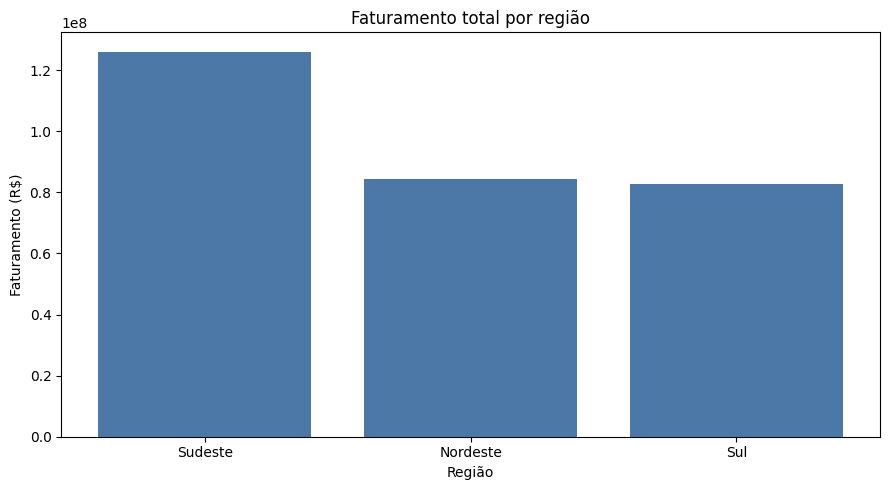

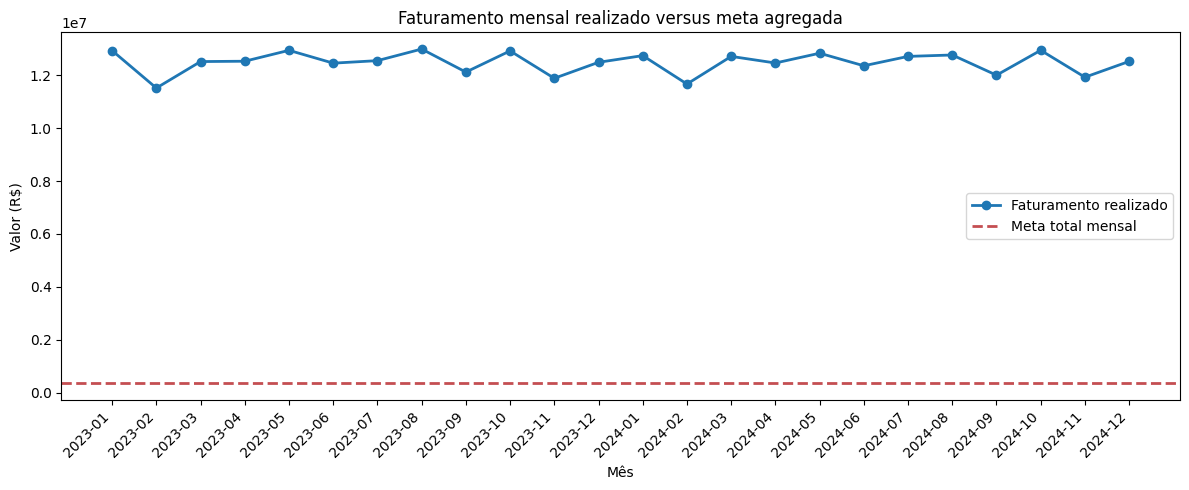

In [41]:
# Gráfico 1: faturamento por região.
plt.figure(figsize=(9, 5))
plt.bar(df_faturamento_por_regiao["Regiao"], df_faturamento_por_regiao["Faturamento"], color="#4C78A8")
plt.title("Faturamento total por região")
plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")
plt.tight_layout()
plt.show()

# Gráfico 2: faturamento mensal agregado e meta mensal agregada.
faturamento_mensal = (
    df_vendas_meta.groupby("Mes", as_index=False)
    .agg(Faturamento_Mensal=("Faturamento", "sum"))
    .sort_values("Mes")
)
meta_mensal_total = df_gerentes_meta["Meta_Mensal"].sum()
plt.figure(figsize=(12, 5))
plt.plot(faturamento_mensal["Mes"], faturamento_mensal["Faturamento_Mensal"], marker="o", linewidth=2, label="Faturamento realizado")
plt.axhline(meta_mensal_total, color="#C44E52", linestyle="--", linewidth=2, label="Meta total mensal")
plt.title("Faturamento mensal realizado versus meta agregada")
plt.xlabel("Mês")
plt.ylabel("Valor (R$)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

# Conclusão do projeto

O Sudeste lidera o faturamento regional, mas as médias de faturamento por loja são semelhantes nas três regiões: Nordeste, Sudeste e Sul apresentam resultados próximos.

Todos os sete gerentes atingiram suas metas em todos os 24 meses analisados. Porém, as metas individuais estão muito abaixo das vendas reais: juntas, somam apenas R$ 352 mil por mês, enquanto o faturamento médio mensal supera R$ 12 milhões.

Os gráficos confirmam essa diferença expressiva e mostram que as metas não representam um desafio relevante com o nível atual de vendas. Como a meta agregada foi definida nesse patamar, recomenda-se revisá-las periodicamente para torná-las mais exigentes e alinhadas ao potencial real do negócio.